# Cvičení: Detekce anomálií pomocí Local Outlier Factor (LOF)

**Cíle cvičení:**
1. Načíst syntetický shlukový dataset `blobs_dataset.csv`.
2. Připravit data a provést standardizaci příznaků (`StandardScaler`).
3. Natrénovat model `LocalOutlierFactor` s předpokladem 2 % anomálií (`contamination=0.02`) a zvolit počet sousedů $k=20$.
4. Vizualizovat odhalené anomálie v porovnání s běžnými body.
5. Otestovat a graficky porovnat chování modelu při zvýšení kontaminace na 5 % (`contamination=0.05`).
6. Analyzovat, jak se mění klasifikace hraničních bodů a jaký je business dopad kalibrace prahu.

In [1]:
# Import potřebných knihoven
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

# Nastavení vizualizačního stylu
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
print('Knihovny úspěšně importovány.')

Knihovny úspěšně importovány.


## 1. Načtení datasetu blobs_dataset.csv

Dataset načteme pomocí robustního vyhledání souboru, které funguje jak lokálně, tak v prostředí Google Colab.

In [2]:
# Robustní načtení dat
data_candidates = [
    Path('../data/Downloadable materials for Session 3/blobs_dataset.csv'),
    Path('data/Downloadable materials for Session 3/blobs_dataset.csv'),
    Path('../data/blobs_dataset.csv'),
    Path('data/blobs_dataset.csv'),
    Path('blobs_dataset.csv')
]

csv_path = None
for cand in data_candidates:
    if cand.exists():
        csv_path = cand
        break

if csv_path is None:
    raise FileNotFoundError('Soubor blobs_dataset.csv nebyl nalezen.')

df = pd.read_csv(csv_path)
print(f'Dataset úspěšně načten z: {csv_path}')
print(f'Rozměry datasetu: {df.shape[0]} řádků, {df.shape[1]} sloupců')
df.head()

Dataset úspěšně načten z: ..\data\Downloadable materials for Session 3\blobs_dataset.csv
Rozměry datasetu: 1000 řádků, 2 sloupců


,feature_1,feature_2
0,-1.619896,-2.576770
1,-3.700501,9.670840
2,-5.339438,-5.739383
3,4.964045,1.843027
4,-1.834939,-4.189869


## 2. Průzkumná analýza dat (EDA)

Zkontrolujeme základní statistiky a vizualizujeme výchozí prostor bodů.

,feature_1,feature_2
count,1000.0000,1000.0000
mean,-2.5856,0.9780
std,5.4162,6.2245
min,-12.0877,-9.2533
25%,-7.1592,-5.2284
50%,-3.3380,1.3734
75%,2.0876,7.2318
max,8.9682,12.8670


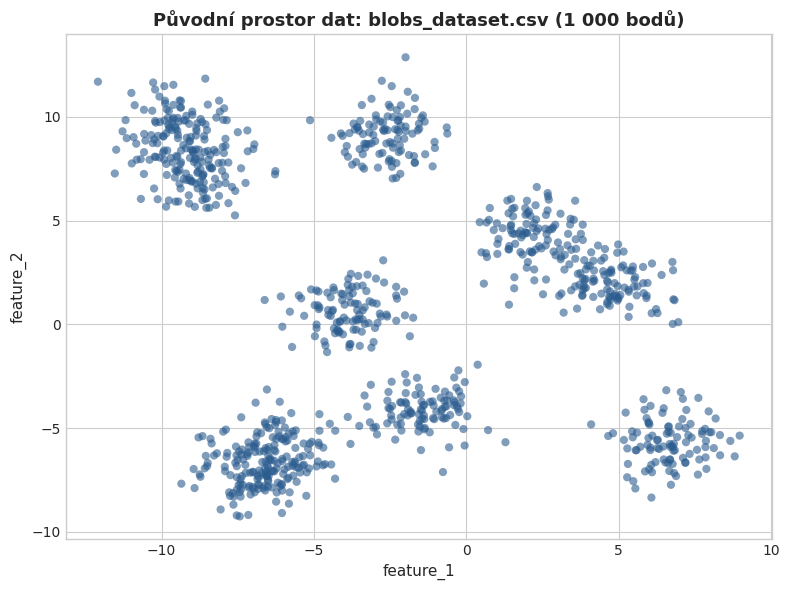

In [3]:
# Základní popisné statistiky
display(df.describe().round(4))

# Vykreslení původního bodového grafu
plt.figure(figsize=(8, 6))
plt.scatter(df['feature_1'], df['feature_2'], c='#2b5c8f', alpha=0.6, edgecolors='none', s=35)
plt.title('Původní prostor dat: blobs_dataset.csv (1 000 bodů)', fontsize=13, fontweight='bold')
plt.xlabel('feature_1', fontsize=11)
plt.ylabel('feature_2', fontsize=11)
plt.tight_layout()
plt.show()

## 3. Standardizace dat

Algoritmus LOF je založen na eukleidovské vzdálenosti ($k$-NN). Standardizace zajistí, že obě proměnné mají nulový průměr a jednotkový rozptyl.

In [4]:
# Standardizace příznaků
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[['feature_1', 'feature_2']])

df_scaled = pd.DataFrame(X_scaled, columns=['feature_1_scaled', 'feature_2_scaled'])
print('Data úspěšně standardizována.')
df_scaled.describe().round(4)

Data úspěšně standardizována.


,feature_1_scaled,feature_2_scaled
count,1000.0000,1000.0000
mean,0.0000,0.0000
std,1.0005,1.0005
min,-1.7553,-1.6445
25%,-0.8449,-0.9976
50%,-0.1390,0.0636
75%,0.8632,1.0052
max,2.1343,1.9110


## 4. Model A: Local Outlier Factor s kontaminací 2 %

Nastavíme `contamination=0.02` a počet sousedů `n_neighbors=20`.

In [5]:
# Trénování LOF s kontaminací 2 %
lof_02 = LocalOutlierFactor(n_neighbors=20, contamination=0.02)
y_pred_02 = lof_02.fit_predict(X_scaled)
df['is_outlier_02'] = (y_pred_02 == -1)
df['lof_score'] = -lof_02.negative_outlier_factor_

n_outliers_02 = (y_pred_02 == -1).sum()
threshold_02 = -lof_02.offset_
print(f'Počet detekovaných anomálií při 2% kontaminaci: {n_outliers_02}')
print(f'Rozhodovací práh LOF: {threshold_02:.4f}')

Počet detekovaných anomálií při 2% kontaminaci: 20
Rozhodovací práh LOF: 1.7295


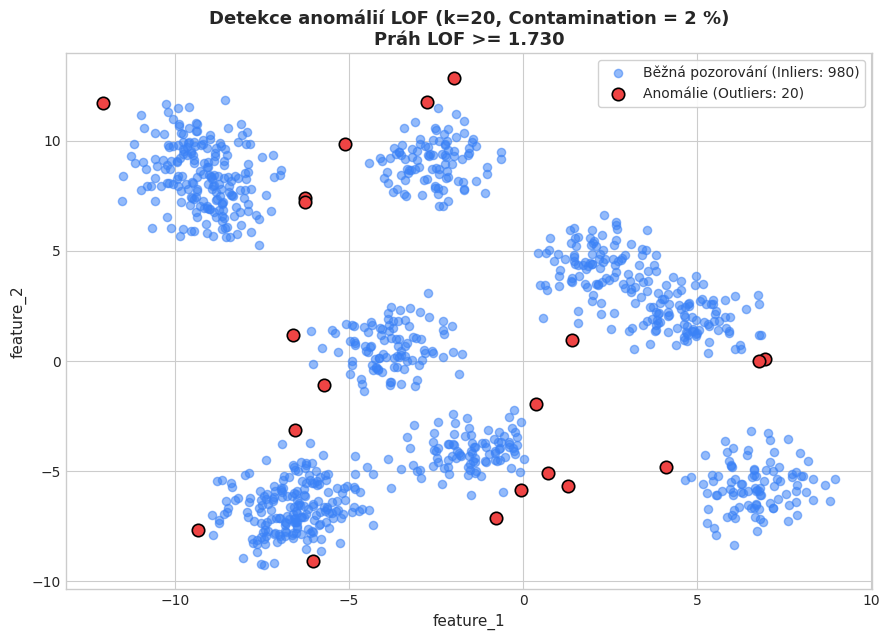

In [6]:
# Vizualizace anomálií při 2% kontaminaci
plt.figure(figsize=(9, 6.5))
plt.scatter(df.loc[~df['is_outlier_02'], 'feature_1'],
            df.loc[~df['is_outlier_02'], 'feature_2'],
            c='#3b82f6', label='Běžná pozorování (Inliers: 980)', alpha=0.55, s=35)
plt.scatter(df.loc[df['is_outlier_02'], 'feature_1'],
            df.loc[df['is_outlier_02'], 'feature_2'],
            c='#ef4444', label=f'Anomálie (Outliers: {n_outliers_02})', s=80, edgecolors='black', linewidth=1.2, zorder=5)
plt.title(f'Detekce anomálií LOF (k=20, Contamination = 2 %)\nPráh LOF >= {threshold_02:.3f}', fontsize=13, fontweight='bold')
plt.xlabel('feature_1', fontsize=11)
plt.ylabel('feature_2', fontsize=11)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()

## 5. Model B: Local Outlier Factor s kontaminací 5 %

Nyní zvýšíme parametr kontaminace na `contamination=0.05` při zachování stejného počtu sousedů `n_neighbors=20`.

In [7]:
# Trénování LOF s kontaminací 5 %
lof_05 = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
y_pred_05 = lof_05.fit_predict(X_scaled)
df['is_outlier_05'] = (y_pred_05 == -1)

n_outliers_05 = (y_pred_05 == -1).sum()
threshold_05 = -lof_05.offset_
print(f'Počet detekovaných anomálií při 5% kontaminaci: {n_outliers_05}')
print(f'Rozhodovací práh LOF: {threshold_05:.4f}')

Počet detekovaných anomálií při 5% kontaminaci: 50
Rozhodovací práh LOF: 1.5044


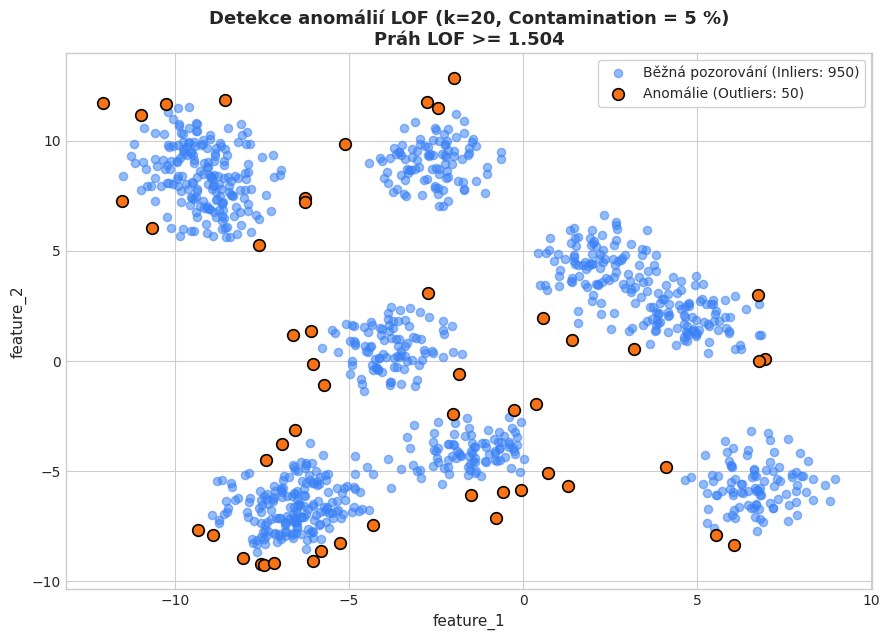

In [8]:
# Vizualizace anomálií při 5% kontaminaci
plt.figure(figsize=(9, 6.5))
plt.scatter(df.loc[~df['is_outlier_05'], 'feature_1'],
            df.loc[~df['is_outlier_05'], 'feature_2'],
            c='#3b82f6', label='Běžná pozorování (Inliers: 950)', alpha=0.55, s=35)
plt.scatter(df.loc[df['is_outlier_05'], 'feature_1'],
            df.loc[df['is_outlier_05'], 'feature_2'],
            c='#f97316', label=f'Anomálie (Outliers: {n_outliers_05})', s=70, edgecolors='black', linewidth=1.2, zorder=5)
plt.title(f'Detekce anomálií LOF (k=20, Contamination = 5 %)\nPráh LOF >= {threshold_05:.3f}', fontsize=13, fontweight='bold')
plt.xlabel('feature_1', fontsize=11)
plt.ylabel('feature_2', fontsize=11)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()

## 6. Srovnávací analýza a vizualizace přidaných anomálií

Klíčový dotaz zadání: **Jak se graf změní, když předpokládáme 5 % anomálií místo 2 %?**

1. Body označené jako anomálie při 2 % jsou **striktní podmnožinou** anomálií při 5 %.
2. Přibývá přesně **30 nových anomálií**, které představují hraniční body na periferii shluků.

In [9]:
# Klasifikace přechodu bodů mezi modely
def get_transition_label(row):
    if row['is_outlier_02'] and row['is_outlier_05']:
        return 'Extrémní anomálie (2 % i 5 %)'
    elif not row['is_outlier_02'] and row['is_outlier_05']:
        return 'Přidaná anomálie (pouze při 5 %)'
    else:
        return 'Běžné pozorování (Inlier)'

df['transition_category'] = df.apply(get_transition_label, axis=1)

print('Rozložení kategorií po změně kontaminace:')
print(df['transition_category'].value_counts())

Rozložení kategorií po změně kontaminace:


transition_category
Běžné pozorování (Inlier)           950
Přidaná anomálie (pouze při 5 %)     30
Extrémní anomálie (2 % i 5 %)        20
Name: count, dtype: int64


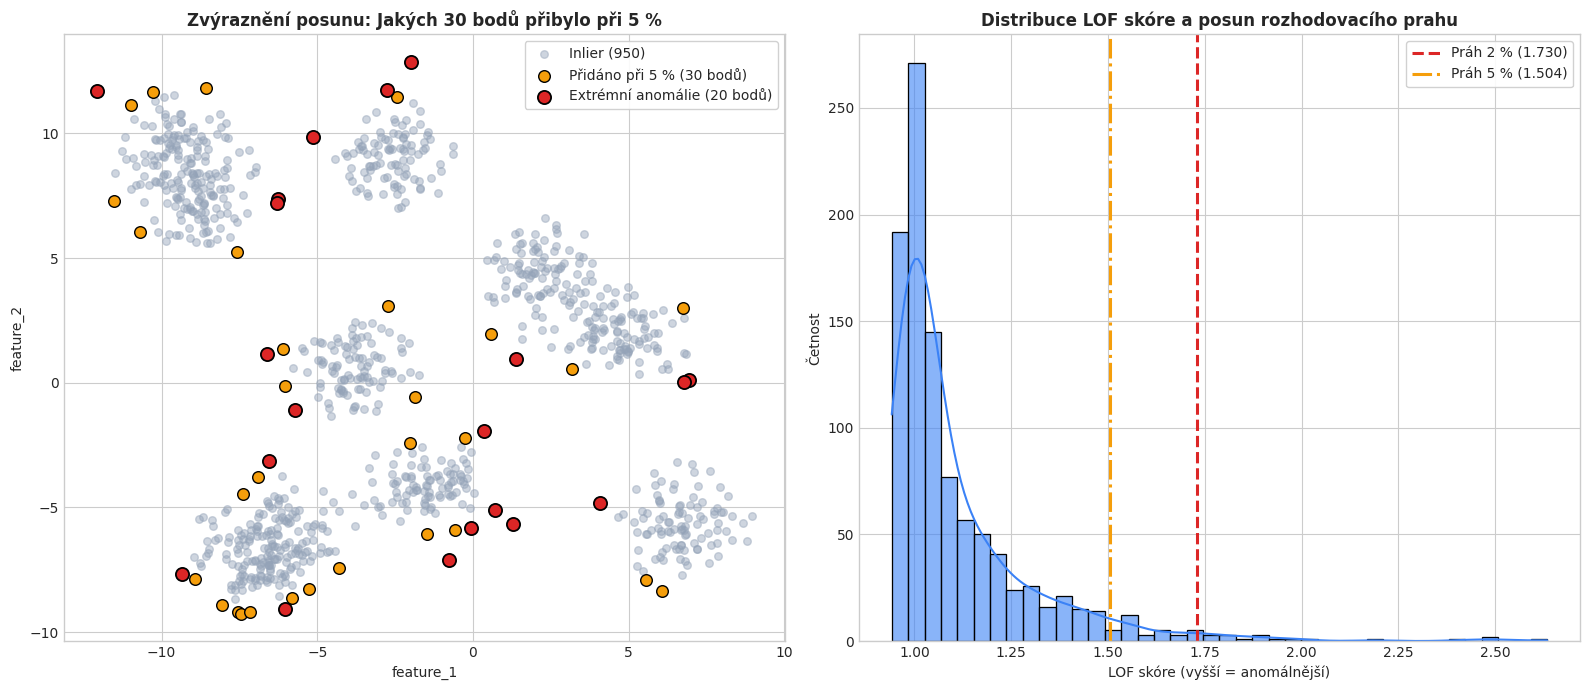

In [10]:
# Přímé srovnání: Vykreslení vedle sebe a detail přechodových bodů
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Levý graf: 2 % vs 5 % side-by-side
axes[0].scatter(df.loc[df['transition_category'] == 'Běžné pozorování (Inlier)', 'feature_1'],
                df.loc[df['transition_category'] == 'Běžné pozorování (Inlier)', 'feature_2'],
                c='#94a3b8', alpha=0.45, s=30, label='Inlier (950)')
axes[0].scatter(df.loc[df['transition_category'] == 'Přidaná anomálie (pouze při 5 %)', 'feature_1'],
                df.loc[df['transition_category'] == 'Přidaná anomálie (pouze při 5 %)', 'feature_2'],
                c='#f59e0b', s=70, edgecolors='black', linewidth=1, label='Přidáno při 5 % (30 bodů)')
axes[0].scatter(df.loc[df['transition_category'] == 'Extrémní anomálie (2 % i 5 %)', 'feature_1'],
                df.loc[df['transition_category'] == 'Extrémní anomálie (2 % i 5 %)', 'feature_2'],
                c='#dc2626', s=90, edgecolors='black', linewidth=1.3, label='Extrémní anomálie (20 bodů)')
axes[0].set_title('Zvýraznění posunu: Jakých 30 bodů přibylo při 5 %', fontsize=12, fontweight='bold')
axes[0].set_xlabel('feature_1')
axes[0].set_ylabel('feature_2')
axes[0].legend(frameon=True, facecolor='white', framealpha=0.9)

# Pravý graf: Distribuce LOF skóre a rozhodovací prahy
sns.histplot(df['lof_score'], bins=40, kde=True, ax=axes[1], color='#3b82f6', alpha=0.6)
axes[1].axvline(threshold_02, color='#dc2626', linestyle='--', linewidth=2.2, label=f'Práh 2 % ({threshold_02:.3f})')
axes[1].axvline(threshold_05, color='#f59e0b', linestyle='-.', linewidth=2.2, label=f'Práh 5 % ({threshold_05:.3f})')
axes[1].set_title('Distribuce LOF skóre a posun rozhodovacího prahu', fontsize=12, fontweight='bold')
axes[1].set_xlabel('LOF skóre (vyšší = anomálnější)')
axes[1].set_ylabel('Četnost')
axes[1].legend(frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()

## 7. Závěry a shrnutí cvičení

1. **Samotná skóre LOF jsou invariantní vůči parametru kontaminace** – lokální hustota a poměry hustot bodů závisejí pouze na matici vzdáleností a parametru $k=20$.
2. **Vliv kontaminace na práh:**
   - Při `contamination=0.02` byl rozhodovací práh **1.730** $\rightarrow$ detekováno 20 nejextrémnějších, zcela izolovaných anomálií.
   - Při `contamination=0.05` práh klesl na **1.504** $\rightarrow$ detekováno 50 anomálií.
3. **Charakter přidaných bodů:** Nových 30 anomálií se nenachází v izolovaném prostoru, nýbrž na vnějším okraji (periferii) jednotlivých shluků.
4. **Praktické doporučení:** V praxi by volba závisela na nákladech na falešný poplach vs. nezachycenou anomálii. Pokud je vyšetřování anomálie drahé, volíme 2 %; pokud hrozí fatální škoda z přehlédnutí, volíme 5 %.